In [1]:
import sys, os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'
sys.path.append('../src')

import torch
import numpy as np
import matplotlib.pyplot as plt
import torch.nn.functional as F
import pickle

from models.dreamrec_text import DreamRecText
from data import build_dataloaders

plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.spines.top']   = False
plt.rcParams['axes.spines.right'] = False

In [14]:
# ════════════════════════════════════════════════════════════
# КОНФИГ
# ════════════════════════════════════════════════════════════
CKPT_DIR        = '../checkpoints/dreamrec_text_pca_l2_nocfg'
DATA_DIR        = '../data/ATG'
EMB_PATH        = '../data/ATG/3large_emb.pickle'
WHITENING_CACHE = '../data/processed/whitening_cache.npz'
N_ITEMS    = 11924
PADDING    = 11924
N_SAMPLES  = 1000
BATCH_SIZE = 1024
SEED       = 42

# w_cfg при сэмплировании (None = брать из чекпойнта)
W_CFG_OVERRIDE = 0.0

import random, numpy as np
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')

Device: cuda


In [15]:
# Загружаем чекпойнт и модель
from pathlib import Path

ckpt_path = Path(CKPT_DIR) / 'best.pt'
if not ckpt_path.exists():
    ckpt_path = Path(CKPT_DIR) / 'latest.pt'
print(f'Checkpoint: {ckpt_path}')

ckpt = torch.load(ckpt_path, map_location=device)
sd   = ckpt['model_state']
print(f'epoch={ckpt.get("epoch")}, metrics={ckpt.get("metrics")}')

# Определяем архитектуру из state_dict
use_pca     = 'whitening_V' in sd
n_components = sd['whitening_V'].shape[1] if use_pca else None
T           = sd['betas'].shape[0]
cfg         = ckpt.get('model_cfg', {})
w_cfg_ckpt  = cfg.get('w_cfg', 0.0)
w_cfg       = W_CFG_OVERRIDE if W_CFG_OVERRIDE is not None else w_cfg_ckpt
d_emb       = cfg.get('d_emb', sd['item_embedding.weight'].shape[1])
print(f'use_pca={use_pca}, n_components={n_components}, d_emb={d_emb}, T={T}, w_cfg={w_cfg}')

# Загружаем сырые эмбеддинги (нужны для инициализации DreamRecText)
print('Loading raw embeddings...')
with open(EMB_PATH, 'rb') as f:
    emb_raw = pickle.load(f).astype(np.float32)
print(f'  {emb_raw.shape}')

model = DreamRecText(
    item_embeddings_raw=emb_raw,
    padding_idx=PADDING,
    use_pca=use_pca,
    n_components=n_components if n_components else 256,
    whitening_cache_path=WHITENING_CACHE,
    T=T,
    w_cfg=w_cfg,
).to(device)
model.load_state_dict(sd)

# EMA weights
ema_shadow = ckpt.get('ema_shadow', {})
if ema_shadow:
    for name, param in model.named_parameters():
        if name in ema_shadow:
            param.data.copy_(ema_shadow[name].to(device))
    print('EMA weights loaded')

model.eval()
summary = model.param_summary()
print(f'Trainable: {summary["total_trainable"]:,}, Frozen: {summary["total_frozen"]:,}')
print('Model ready')

Checkpoint: ..\checkpoints\dreamrec_text_pca_l2_nocfg\best.pt
epoch=430, metrics={'HR@10': 0.013910355046391487, 'NDCG@10': 0.010729004628956318, 'HR@20': 0.014940752647817135, 'NDCG@20': 0.01100354827940464}
use_pca=True, n_components=256, d_emb=256, T=1000, w_cfg=0.0
Loading raw embeddings...
  (11924, 3072)
Loading whitening from cache: ..\data\processed\whitening_cache.npz
EMA weights loaded
Trainable: 1,581,056, Frozen: 3,052,800
Model ready


In [4]:
# Загружаем все сплиты
import pandas as pd
loaders = build_dataloaders(data_dir=DATA_DIR, batch_size=BATCH_SIZE,
                             num_workers=0, splits=('train', 'val', 'test'))
print(f'Train: {len(loaders["train"].dataset):,} sequences')
print(f'Val:   {len(loaders["val"].dataset):,} sequences')
print(f'Test:  {len(loaders["test"].dataset):,} sequences')

Train: 15,529 sequences
Val:   1,941 sequences
Test:  1,942 sequences


In [5]:

# ════════════════════════════════════════════════════════════
# Вспомогательные функции
# ════════════════════════════════════════════════════════════

from pathlib import Path

_train_df  = pd.read_pickle(Path(DATA_DIR) / 'train_data.df')
_freq      = _train_df['next'].value_counts()
_freq_all  = pd.Series(0, index=range(N_ITEMS)); _freq_all.update(_freq)
_freq_vals = _freq_all.values.astype(float)
with torch.no_grad():
    _norms = model.item_embedding.weight[:N_ITEMS].norm(dim=-1).cpu().numpy()
_mask = _freq_vals > 0
TRAIN_TARGET_NORM = float((_norms[_mask] * _freq_vals[_mask]).sum() / _freq_vals[_mask].sum())
print(f'E[||e_target||] по train = {TRAIN_TARGET_NORM:.3f}')
print(f'd_emb = {model.d_emb}, E[||noise||] = sqrt({model.d_emb}) = {np.sqrt(model.d_emb):.2f}')


@torch.no_grad()
def sample_with_tracking(model, h, target_emb):
    B  = h.shape[0]
    W  = model.item_embedding.weight[:model.n_items]
    rand_idx   = torch.randint(0, model.n_items, (B,), device=h.device)
    random_emb = W[rand_idx]
    x = torch.randn_like(h)
    tracking = {k: [] for k in [
        'step', 'l2_target', 'l2_random', 'norm_x', 'cos_target', 'cos_random',
    ]}
    def record(step, x_cur):
        tracking['step'].append(step)
        for name, ref in [('target', target_emb), ('random', random_emb)]:
            tracking[f'l2_{name}'].append((x_cur - ref).pow(2).sum(-1).sqrt().mean().item())
            tracking[f'cos_{name}'].append(F.cosine_similarity(x_cur, ref, dim=-1).mean().item())
        tracking['norm_x'].append(x_cur.norm(dim=-1).mean().item())
    record(0, x)
    for i, t_idx in enumerate(reversed(range(model.T))):
        x = model.p_sample(x, h, t_idx)
        record(i + 1, x)
    return tracking


def hit_ratio(rankings, targets, k):
    return (rankings[:, :k] == targets.unsqueeze(-1)).any(dim=-1).float().mean().item()


def ndcg(rankings, targets, k):
    top_k   = rankings[:, :k]
    matches = (top_k == targets.unsqueeze(-1))
    rank    = matches.float().argmax(dim=-1)
    hit     = matches.any(dim=-1)
    return (1.0 / torch.log2(rank.float() + 2.0) * hit.float()).mean().item()


def _rank_by_metric(oracle, W, metric):
    """Возвращает top-20 индексы по заданной метрике дистанции."""
    if metric == 'Dot Product':
        return (oracle @ W.T).topk(20, dim=-1).indices.cpu()
    elif metric == 'Cosine Sim':
        return (F.normalize(oracle, dim=-1) @ F.normalize(W, dim=-1).T).topk(20, dim=-1).indices.cpu()
    elif metric == 'L2 Distance':
        l2_sq = (oracle.pow(2).sum(-1, keepdim=True) - 2.0 * oracle @ W.T
                 + W.pow(2).sum(-1).unsqueeze(0))
        return l2_sq.topk(20, dim=-1, largest=False).indices.cpu()
    else:
        raise ValueError(f"Unknown metric: {metric!r}. Use 'Dot Product', 'Cosine Sim', or 'L2 Distance'.")


@torch.no_grad()
def compute_metrics(model, loader, seed):
    """Только метрики, один запуск с заданным seed."""
    W = model.item_embedding.weight[:model.n_items].detach()
    torch.manual_seed(seed)
    r_dot, r_cos, r_l2, r_rnd = [], [], [], []
    all_targets = []
    total_loss, n_loss = 0.0, 0

    for batch in loader:
        history = batch['history'].to(device)
        mask    = batch['mask'].to(device)
        target  = batch['target'].to(device)
        B       = history.shape[0]

        z_0      = model.item_embedding(target)
        t        = torch.randint(0, model.T, (B,), device=device)
        eps      = torch.randn_like(z_0)
        x_t      = model.sqrt_alphas_cumprod[t].unsqueeze(1) * z_0 + \
                   model.sqrt_one_minus_alphas_cumprod[t].unsqueeze(1) * eps
        h        = model.encode_history(history, mask, apply_cfg_dropout=False)
        total_loss += F.mse_loss(model.forward(x_t, h, t), z_0).item()
        n_loss += 1

        oracle = model.sample(h)
        r_dot.append(_rank_by_metric(oracle, W, 'Dot Product'))
        r_cos.append(_rank_by_metric(oracle, W, 'Cosine Sim'))
        r_l2.append(_rank_by_metric(oracle, W, 'L2 Distance'))
        r_rnd.append(torch.stack([torch.randperm(model.n_items)[:20] for _ in range(B)]))
        all_targets.append(target.cpu())

    targets_all = torch.cat(all_targets, dim=0)
    loss_val    = total_loss / n_loss
    rows = {}
    for name, rlist in [('Dot Product', r_dot), ('Cosine Sim', r_cos),
                        ('L2 Distance', r_l2),  ('Random',     r_rnd)]:
        r = torch.cat(rlist, dim=0)
        rows[name] = {
            'HR@10':   hit_ratio(r, targets_all, 10),
            'NDCG@10': ndcg(r, targets_all, 10),
            'HR@20':   hit_ratio(r, targets_all, 20),
            'NDCG@20': ndcg(r, targets_all, 20),
        }
    return rows, loss_val


@torch.no_grad()
def compute_metrics_shuffled(model, loader, seed, metric='L2 Distance'):
    """Метрики с перемешанными историями. metric: 'Dot Product', 'Cosine Sim', 'L2 Distance'."""
    W = model.item_embedding.weight[:model.n_items].detach()
    torch.manual_seed(seed)
    rankings = []
    all_targets = []

    for batch in loader:
        history = batch['history'].to(device)
        mask    = batch['mask'].to(device)
        target  = batch['target'].to(device)
        B       = history.shape[0]

        perm   = torch.randperm(B, device=device)
        h      = model.encode_history(history[perm], mask[perm], apply_cfg_dropout=False)
        oracle = model.sample(h)

        rankings.append(_rank_by_metric(oracle, W, metric))
        all_targets.append(target.cpu())

    targets_all = torch.cat(all_targets, dim=0)
    r = torch.cat(rankings, dim=0)
    return {
        'HR@10':   hit_ratio(r, targets_all, 10),
        'NDCG@10': ndcg(r, targets_all, 10),
        'HR@20':   hit_ratio(r, targets_all, 20),
        'NDCG@20': ndcg(r, targets_all, 20),
    }


@torch.no_grad()
def analyze_split(model, loader, split_name, n_samples=N_SAMPLES, seed=SEED,
                  n_runs=5):
    """Строит траекторию (1 раз) + метрики с mean±std (n_runs раз)."""
    W = model.item_embedding.weight[:model.n_items].detach()

    # ── Трекинг траектории ────────────────────────────────────
    torch.manual_seed(seed)
    track_keys = ['l2_target', 'l2_random', 'norm_x', 'cos_target', 'cos_random']
    acc = {k: None for k in track_keys}
    n_track, n_track_batches = 0, 0
    for batch in loader:
        if n_track >= n_samples:
            break
        history = batch['history'].to(device)
        mask    = batch['mask'].to(device)
        target  = batch['target'].to(device)
        h          = model.encode_history(history, mask, apply_cfg_dropout=False)
        target_emb = model.item_embedding(target)
        tr = sample_with_tracking(model, h, target_emb)
        for k in track_keys:
            arr = np.array(tr[k])
            acc[k] = arr if acc[k] is None else acc[k] + arr
        n_track += history.shape[0]
        n_track_batches += 1
    for k in track_keys:
        acc[k] /= n_track_batches
    steps = np.array(tr['step'])

    fig, axes = plt.subplots(1, 3, figsize=(18, 4))
    ax = axes[0]
    ax.plot(steps, acc['l2_target'], color='tomato',    lw=2, label='Target item')
    ax.plot(steps, acc['l2_random'], color='steelblue', lw=2, label='Random item', ls='--')
    ax.set_title('L2 Distance', fontsize=12); ax.set_xlabel('Sampling step'); ax.set_ylabel('↓ closer')
    ax.legend(fontsize=9); ax.set_xlim(0, len(steps) - 1)
    ax = axes[1]
    ax.plot(steps, acc['norm_x'], color='mediumorchid', lw=2, label='||x_t||')
    noise_norm = np.sqrt(model.d_emb)
    ax.axhline(noise_norm, color='steelblue', ls='--', lw=1.2, label=f'E[||x_T||] ≈ {noise_norm:.1f}')
    ax.axhline(TRAIN_TARGET_NORM, color='tomato', ls='--', lw=1.2, label=f'E[||e_target||] ≈ {TRAIN_TARGET_NORM:.2f}')
    ax.set_title('Норма x_t', fontsize=12); ax.set_xlabel('Sampling step'); ax.set_ylabel('||x_t||')
    ax.legend(fontsize=9); ax.set_xlim(0, len(steps) - 1); ax.set_ylim(bottom=0)
    ax = axes[2]
    ax.plot(steps, acc['cos_target'], color='tomato',    lw=2, label='Target item')
    ax.plot(steps, acc['cos_random'], color='steelblue', lw=2, label='Random item', ls='--')
    ax.set_title('Cosine Similarity', fontsize=12); ax.set_xlabel('Sampling step'); ax.set_ylabel('↑ closer')
    ax.legend(fontsize=9); ax.set_xlim(0, len(steps) - 1)
    plt.suptitle(
        f'{split_name.upper()} — DreamRecText trajectory  '
        f'(use_pca={model.use_pca}, d_emb={model.d_emb}, T={model.T}, {n_track} samples)',
        fontsize=12, y=1.02)
    plt.tight_layout(); plt.show()

    # ── Метрики: n_runs прогонов с разным шумом ───────────────
    seeds = [seed + i * 100 for i in range(n_runs)]
    print(f'{split_name.capitalize()} — метрики ({n_runs} запусков, mean ± std):\n')
    all_runs = {name: {m: [] for m in ['HR@10', 'NDCG@10', 'HR@20', 'NDCG@20']}
                for name in ['Dot Product', 'Cosine Sim', 'L2 Distance', 'Random']}
    losses = []
    for i, s in enumerate(seeds):
        print(f'  Run {i+1}/{n_runs} (seed={s})...', end='\r')
        rows, loss_val = compute_metrics(model, loader, s)
        losses.append(loss_val)
        for name, metrics in rows.items():
            for m, v in metrics.items():
                all_runs[name][m].append(v)
    print()

    table_rows = []
    for name in ['Dot Product', 'Cosine Sim', 'L2 Distance', 'Random']:
        row = {'Retrieval': name}
        for m in ['HR@10', 'NDCG@10', 'HR@20', 'NDCG@20']:
            vals = np.array(all_runs[name][m])
            row[m] = f'{vals.mean():.4f} ± {vals.std():.4f}'
        table_rows.append(row)
    df = pd.DataFrame(table_rows).set_index('Retrieval')
    print(f'Loss: {np.mean(losses):.4f} ± {np.std(losses):.4f}\n')
    print(df.to_string())
    print()
    return df, np.mean(losses)


E[||e_target||] по train = 16.027
d_emb = 256, E[||noise||] = sqrt(256) = 16.00


In [6]:
model.eval()
# train_df, train_loss = analyze_split(model, loaders['train'], 'train')

DreamRecText(
  (item_embedding): Embedding(11925, 256, padding_idx=11924)
  (pos_embedding): Embedding(10, 256)
  (none_embedding): Embedding(1, 256)
  (dropout_emb): Dropout(p=0.1, inplace=False)
  (encoder_block): SASRecBlock(
    (norm1): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
    (attn): MultiheadAttention(
      (out_proj): NonDynamicallyQuantizableLinear(in_features=256, out_features=256, bias=True)
    )
    (norm2): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
    (ff): Sequential(
      (0): Linear(in_features=256, out_features=1024, bias=True)
      (1): GELU(approximate='none')
      (2): Dropout(p=0.1, inplace=False)
      (3): Linear(in_features=1024, out_features=256, bias=True)
      (4): Dropout(p=0.1, inplace=False)
    )
  )
  (encoder_norm): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
  (time_mlp): Sequential(
    (0): Linear(in_features=256, out_features=512, bias=True)
    (1): GELU(approximate='none')
    (2): Linear(in_features=

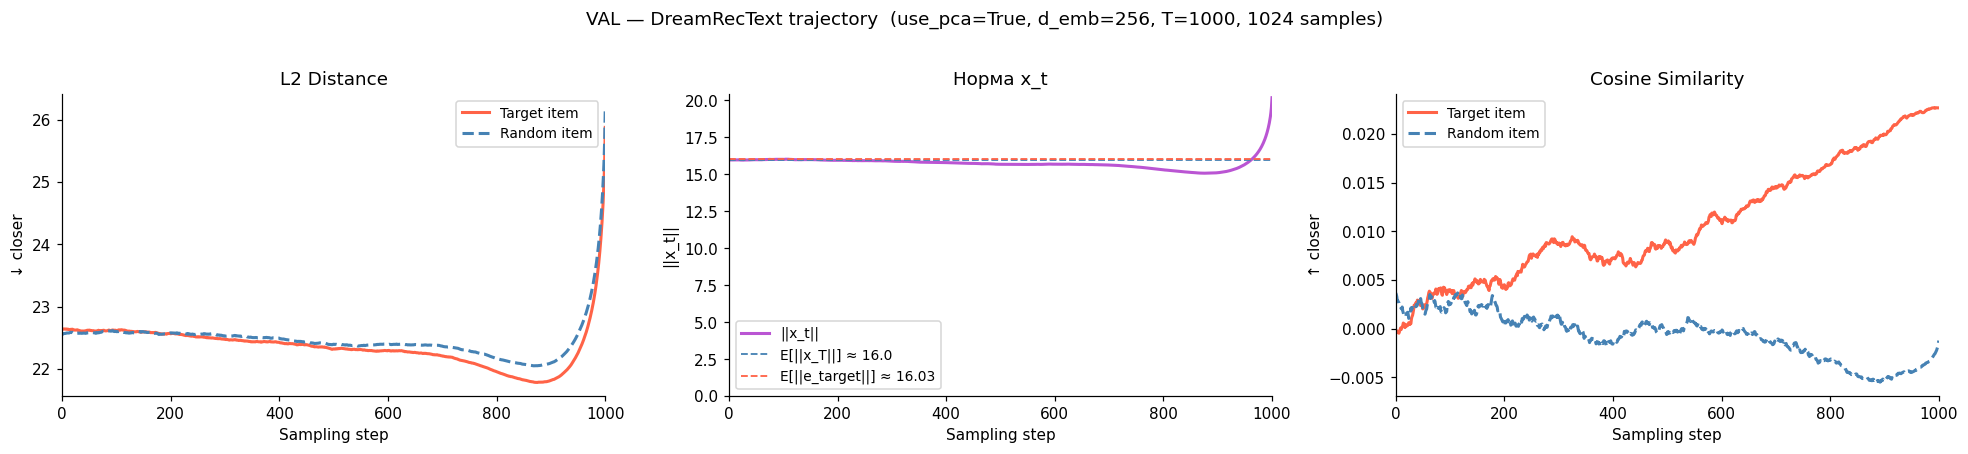

Val — метрики (5 запусков, mean ± std):

  Run 5/5 (seed=442)...
Loss: 0.7743 ± 0.0047

                       HR@10          NDCG@10            HR@20          NDCG@20
Retrieval                                                                      
Dot Product  0.0118 ± 0.0010  0.0091 ± 0.0007  0.0142 ± 0.0010  0.0097 ± 0.0007
Cosine Sim   0.0125 ± 0.0006  0.0098 ± 0.0007  0.0148 ± 0.0004  0.0103 ± 0.0006
L2 Distance  0.0130 ± 0.0005  0.0100 ± 0.0005  0.0148 ± 0.0004  0.0105 ± 0.0003
Random       0.0008 ± 0.0006  0.0003 ± 0.0002  0.0018 ± 0.0003  0.0005 ± 0.0001



In [7]:
val_df, val_loss = analyze_split(model, loaders['val'], 'val')

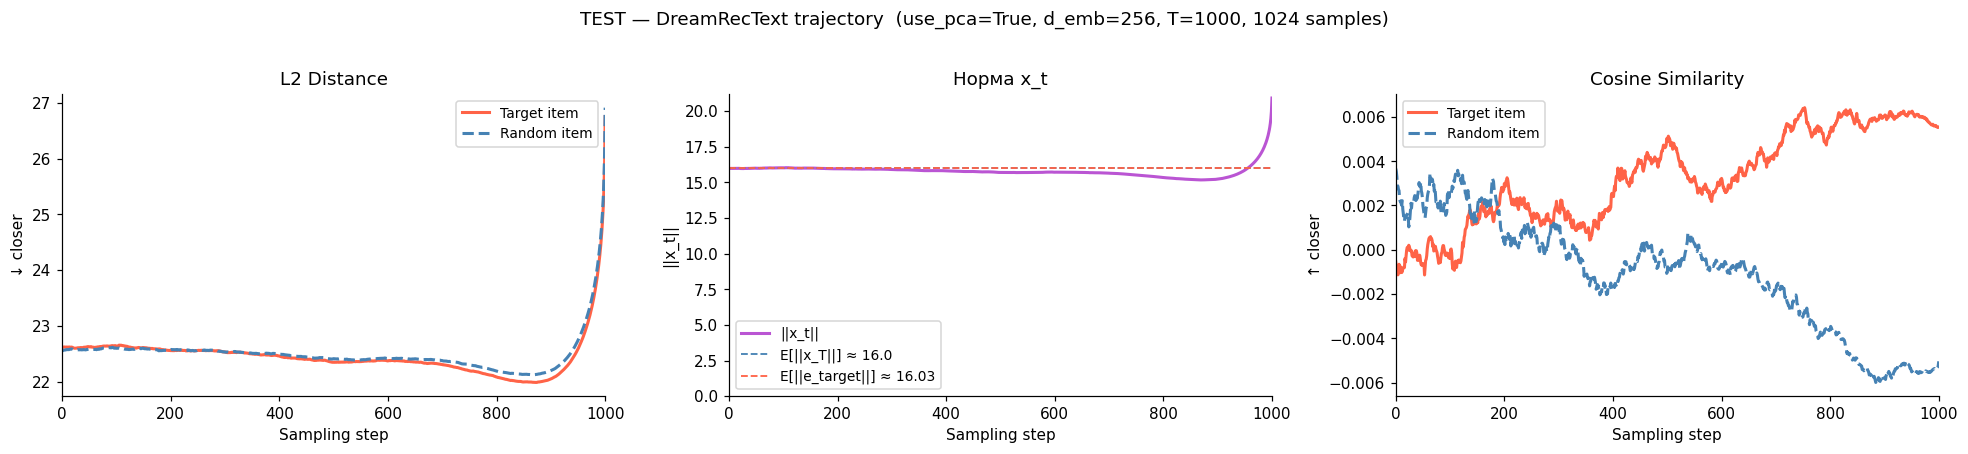

Test — метрики (5 запусков, mean ± std):

  Run 5/5 (seed=442)...
Loss: 0.7779 ± 0.0054

                       HR@10          NDCG@10            HR@20          NDCG@20
Retrieval                                                                      
Dot Product  0.0094 ± 0.0006  0.0089 ± 0.0005  0.0108 ± 0.0006  0.0092 ± 0.0004
Cosine Sim   0.0102 ± 0.0007  0.0090 ± 0.0004  0.0114 ± 0.0004  0.0093 ± 0.0003
L2 Distance  0.0106 ± 0.0004  0.0094 ± 0.0004  0.0118 ± 0.0006  0.0097 ± 0.0004
Random       0.0008 ± 0.0003  0.0004 ± 0.0001  0.0022 ± 0.0005  0.0007 ± 0.0002



In [8]:
test_df, test_loss = analyze_split(model, loaders['test'], 'test')

=== VAL ===
                      HR@10  NDCG@10   HR@20  NDCG@20
Method                                               
Model (L2 Distance)  0.0134   0.0106  0.0155   0.0111
Noise (L2 Distance)  0.0010   0.0007  0.0015   0.0008
Random (analytical)  0.0008   0.0004  0.0017   0.0006

=== TEST ===
                      HR@10  NDCG@10   HR@20  NDCG@20
Method                                               
Model (L2 Distance)  0.0103   0.0091  0.0129   0.0098
Noise (L2 Distance)  0.0005   0.0002  0.0005   0.0002
Random (analytical)  0.0008   0.0004  0.0017   0.0006



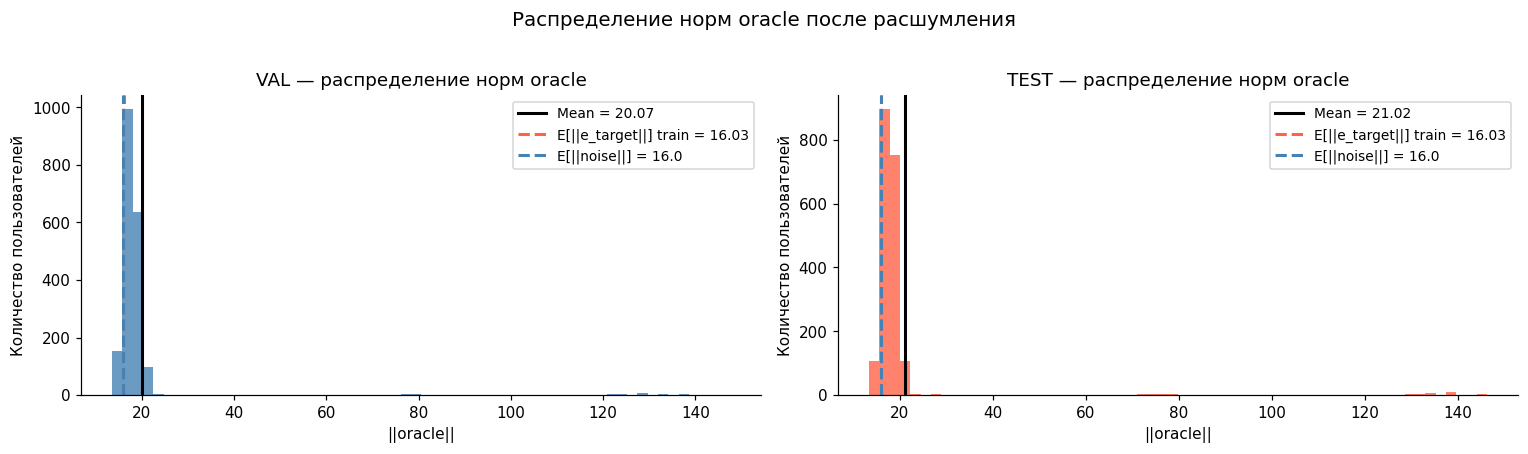

In [9]:

# ════════════════════════════════════════════════════════════
# Сравнение: модель vs шум N(0,I) vs аналитический random
# Сплиты: val и test + распределение норм oracle
# ════════════════════════════════════════════════════════════

# Метрика для сравнения: 'Dot Product', 'Cosine Sim', 'L2 Distance'
COMPARE_METRIC = 'L2 Distance'

torch.manual_seed(SEED)
model.eval()
W = model.item_embedding.weight[:N_ITEMS].detach()

def analytical_random(k):
    hr       = round(k / N_ITEMS, 4)
    ndcg_val = round(sum(1.0 / np.log2(r + 2) for r in range(k)) / N_ITEMS, 4)
    return hr, ndcg_val

hr10_rnd, ndcg10_rnd = analytical_random(10)
hr20_rnd, ndcg20_rnd = analytical_random(20)

results      = {}
oracle_norms = {}

for split_name, loader in [('val', loaders['val']), ('test', loaders['test'])]:
    r_model, r_noise = [], []
    all_targets = []
    all_oracle_norms = []

    with torch.no_grad():
        for batch in loader:
            history = batch['history'].to(device)
            mask    = batch['mask'].to(device)
            target  = batch['target'].to(device)
            B       = history.shape[0]

            oracle = model.sample(model.encode_history(history, mask, apply_cfg_dropout=False))
            noise  = torch.randn(B, model.d_emb, device=device)
            r_model.append(_rank_by_metric(oracle, W, COMPARE_METRIC))
            r_noise.append(_rank_by_metric(noise,  W, COMPARE_METRIC))
            all_oracle_norms.append(oracle.norm(dim=-1).cpu())
            all_targets.append(target.cpu())

    targets = torch.cat(all_targets, dim=0)
    oracle_norms[split_name] = torch.cat(all_oracle_norms).numpy()

    model_label = f'Model ({COMPARE_METRIC})'
    noise_label = f'Noise ({COMPARE_METRIC})'
    results[split_name] = {}
    for method, rlist in [(model_label, r_model), (noise_label, r_noise)]:
        r = torch.cat(rlist, dim=0)
        results[split_name][method] = {
            'HR@10':   round(hit_ratio(r, targets, 10), 4),
            'NDCG@10': round(ndcg(r, targets, 10), 4),
            'HR@20':   round(hit_ratio(r, targets, 20), 4),
            'NDCG@20': round(ndcg(r, targets, 20), 4),
        }
    results[split_name]['Random (analytical)'] = {
        'HR@10': hr10_rnd, 'NDCG@10': ndcg10_rnd,
        'HR@20': hr20_rnd, 'NDCG@20': ndcg20_rnd,
    }

for split_name in ['val', 'test']:
    rows = [{'Method': m, **v} for m, v in results[split_name].items()]
    df   = pd.DataFrame(rows).set_index('Method')
    print(f'=== {split_name.upper()} ===')
    print(df.to_string())
    print()

# Распределение норм oracle
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
colors = {'val': 'steelblue', 'test': 'tomato'}

for ax, split_name in zip(axes, ['val', 'test']):
    norms_arr = oracle_norms[split_name]
    ax.hist(norms_arr, bins=60, color=colors[split_name], alpha=0.8, edgecolor='none')
    ax.axvline(norms_arr.mean(), color='black', lw=2,
               label=f'Mean = {norms_arr.mean():.2f}')
    ax.axvline(TRAIN_TARGET_NORM, color='tomato', lw=2, ls='--',
               label=f'E[||e_target||] train = {TRAIN_TARGET_NORM:.2f}')
    ax.axvline(np.sqrt(model.d_emb), color='steelblue', lw=2, ls='--',
               label=f'E[||noise||] = {np.sqrt(model.d_emb):.1f}')
    ax.set_xlabel('||oracle||')
    ax.set_ylabel('Количество пользователей')
    ax.set_title(f'{split_name.upper()} — распределение норм oracle')
    ax.legend(fontsize=9)

plt.suptitle('Распределение норм oracle после расшумления', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()


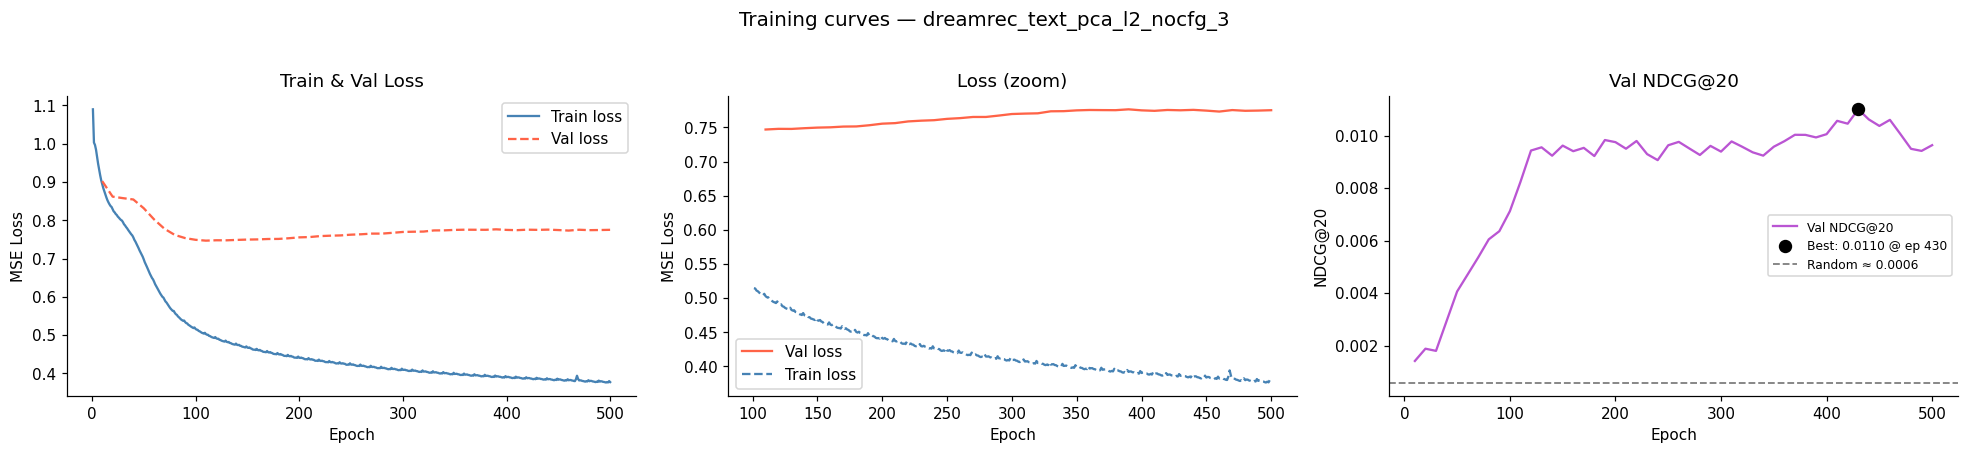

In [10]:

# ════════════════════════════════════════════════════════════
# Кривые обучения: train loss, val loss, NDCG@20 на вале
# ════════════════════════════════════════════════════════════

log_dir = Path(CKPT_DIR)
train_log_path = log_dir / 'log_train.csv'
val_log_path   = log_dir / 'log_val.csv'

if not train_log_path.exists() and not val_log_path.exists():
    print(f'Логи не найдены в {log_dir}')
else:
    train_log = pd.read_csv(train_log_path) if train_log_path.exists() else None
    val_log   = pd.read_csv(val_log_path)   if val_log_path.exists()   else None

    if val_log is not None:
        val_log = val_log[pd.to_numeric(val_log['epoch'], errors='coerce').notna()].copy()
        val_log['epoch']    = val_log['epoch'].astype(int)
        val_log['NDCG@20']  = pd.to_numeric(val_log['NDCG@20'],  errors='coerce')
        val_log['val_loss'] = pd.to_numeric(val_log['val_loss'], errors='coerce')

    if train_log is not None:
        train_log['loss'] = pd.to_numeric(train_log['loss'], errors='coerce')

    fig, axes = plt.subplots(1, 3, figsize=(18, 4))

    ax = axes[0]
    if train_log is not None:
        ax.plot(train_log['epoch'], train_log['loss'], color='steelblue', lw=1.5, label='Train loss')
    if val_log is not None:
        ax.plot(val_log['epoch'], val_log['val_loss'], color='tomato', lw=1.5, ls='--', label='Val loss')
    ax.set_xlabel('Epoch'); ax.set_ylabel('MSE Loss')
    ax.set_title('Train & Val Loss'); ax.legend()

    ax = axes[1]
    if val_log is not None:
        skip_n = len(val_log) // 5
        v = val_log.iloc[skip_n:]
        ax.plot(v['epoch'], v['val_loss'], color='tomato', lw=1.5, label='Val loss')
    if train_log is not None:
        ratio = len(train_log) // max(len(val_log), 1)
        t = train_log.iloc[skip_n * ratio:]
        ax.plot(t['epoch'], t['loss'], color='steelblue', lw=1.5, ls='--', label='Train loss')
    ax.set_xlabel('Epoch'); ax.set_ylabel('MSE Loss')
    ax.set_title('Loss (zoom)'); ax.legend()

    ax = axes[2]
    if val_log is not None:
        ax.plot(val_log['epoch'], val_log['NDCG@20'], color='mediumorchid', lw=1.5, label='Val NDCG@20')
        best_idx  = val_log['NDCG@20'].idxmax()
        best_ep   = val_log.loc[best_idx, 'epoch']
        best_ndcg = val_log.loc[best_idx, 'NDCG@20']
        ax.scatter([best_ep], [best_ndcg], color='black', zorder=5, s=60,
                   label=f'Best: {best_ndcg:.4f} @ ep {best_ep}')
    random_ndcg20 = sum(1.0 / np.log2(r + 2) for r in range(20)) / N_ITEMS
    ax.axhline(random_ndcg20, color='gray', ls='--', lw=1.2,
               label=f'Random ≈ {random_ndcg20:.4f}')
    ax.set_xlabel('Epoch'); ax.set_ylabel('NDCG@20')
    ax.set_title('Val NDCG@20'); ax.legend(fontsize=8)

    plt.suptitle(f'Training curves — {log_dir.name}', fontsize=13, y=1.02)
    plt.tight_layout()
    plt.show()


In [13]:

# ════════════════════════════════════════════════════════════
# Shuffle Test + метрики val/test (5 запусков, mean±std)
# Model vs Model shuffled vs Random
# ════════════════════════════════════════════════════════════

N_RUNS        = 5
BASE_SEED     = SEED
# Метрика для shuffled-теста: 'Dot Product', 'Cosine Sim', 'L2 Distance'
SHUFFLE_METRIC = 'L2 Distance'

# ── Shuffle Test cosine/L2 (один запуск) ─────────────────────
torch.manual_seed(BASE_SEED)
model.eval()
cos_sims, l2_dists = [], []

with torch.no_grad():
    for batch in loaders['val']:
        history = batch['history'].to(device)
        mask    = batch['mask'].to(device)
        B       = history.shape[0]
        h_real          = model.encode_history(history, mask, apply_cfg_dropout=False)
        oracle_real     = model.sample(h_real)
        perm            = torch.randperm(B, device=device)
        h_shuffled      = model.encode_history(history[perm], mask[perm], apply_cfg_dropout=False)
        oracle_shuffled = model.sample(h_shuffled)
        cos_sims.append(F.cosine_similarity(oracle_real, oracle_shuffled, dim=-1).cpu())
        l2_dists.append((oracle_real - oracle_shuffled).norm(dim=-1).cpu())

cos_all = torch.cat(cos_sims)
l2_all  = torch.cat(l2_dists)
print(f'Cosine similarity (real vs shuffled): {cos_all.mean():.4f}  (1.0 = история не влияет)')
print(f'L2 distance       (real vs shuffled): {l2_all.mean():.4f}   (0.0 = история не влияет)')
print(f'L2 random N(0,I):                   ≈ {(2 * model.d_emb) ** 0.5:.2f}')
print()

# ── Метрики val и test ────────────────────────────────────────
METRIC_NAMES = ['HR@10', 'NDCG@10', 'HR@20', 'NDCG@20']
shuffled_label = f'Model shuffled ({SHUFFLE_METRIC})'
ROW_NAMES = [f'Model ({SHUFFLE_METRIC})', shuffled_label, 'Random']

for split_name, loader in [('val', loaders['val']), ('test', loaders['test'])]:
    all_runs = {r: {m: [] for m in METRIC_NAMES} for r in ROW_NAMES}
    losses = []
    for i in range(N_RUNS):
        s = BASE_SEED + i * 100
        print(f'  {split_name} run {i+1}/{N_RUNS} (seed={s})...', end='\r')
        rows_real, loss_val = compute_metrics(model, loader, s)
        losses.append(loss_val)
        for m in METRIC_NAMES:
            all_runs[f'Model ({SHUFFLE_METRIC})'][m].append(rows_real[SHUFFLE_METRIC][m])
            all_runs['Random'][m].append(rows_real['Random'][m])
        rows_shuf = compute_metrics_shuffled(model, loader, s, metric=SHUFFLE_METRIC)
        for m in METRIC_NAMES:
            all_runs[shuffled_label][m].append(rows_shuf[m])
    print()

    table_rows = []
    for name in ROW_NAMES:
        row = {'Retrieval': name}
        for m in METRIC_NAMES:
            vals = np.array(all_runs[name][m])
            row[m] = f'{vals.mean():.4f} ± {vals.std():.4f}'
        table_rows.append(row)
    df = pd.DataFrame(table_rows).set_index('Retrieval')
    print(f'=== {split_name.upper()} | Loss: {np.mean(losses):.4f} ± {np.std(losses):.4f} ===')
    print(df.to_string())
    print()


Cosine similarity (real vs shuffled): 0.0190  (1.0 = история не влияет)
L2 distance       (real vs shuffled): 29.3027   (0.0 = история не влияет)
L2 random N(0,I):                   ≈ 22.63

  val run 5/5 (seed=442)...
=== VAL | Loss: 0.7743 ± 0.0047 ===
                                        HR@10          NDCG@10            HR@20          NDCG@20
Retrieval                                                                                       
Model (L2 Distance)           0.0130 ± 0.0005  0.0100 ± 0.0005  0.0148 ± 0.0004  0.0105 ± 0.0003
Model shuffled (L2 Distance)  0.0010 ± 0.0005  0.0005 ± 0.0002  0.0022 ± 0.0004  0.0007 ± 0.0002
Random                        0.0008 ± 0.0006  0.0003 ± 0.0002  0.0018 ± 0.0003  0.0005 ± 0.0001

  test run 5/5 (seed=442)...
=== TEST | Loss: 0.7779 ± 0.0054 ===
                                        HR@10          NDCG@10            HR@20          NDCG@20
Retrieval                                                                                       

Fitting on 3882 vectors (1941 oracle + 1941 target), d=256
t-SNE done


c:\Users\ilyak\miniconda3\envs\torch_env\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP done


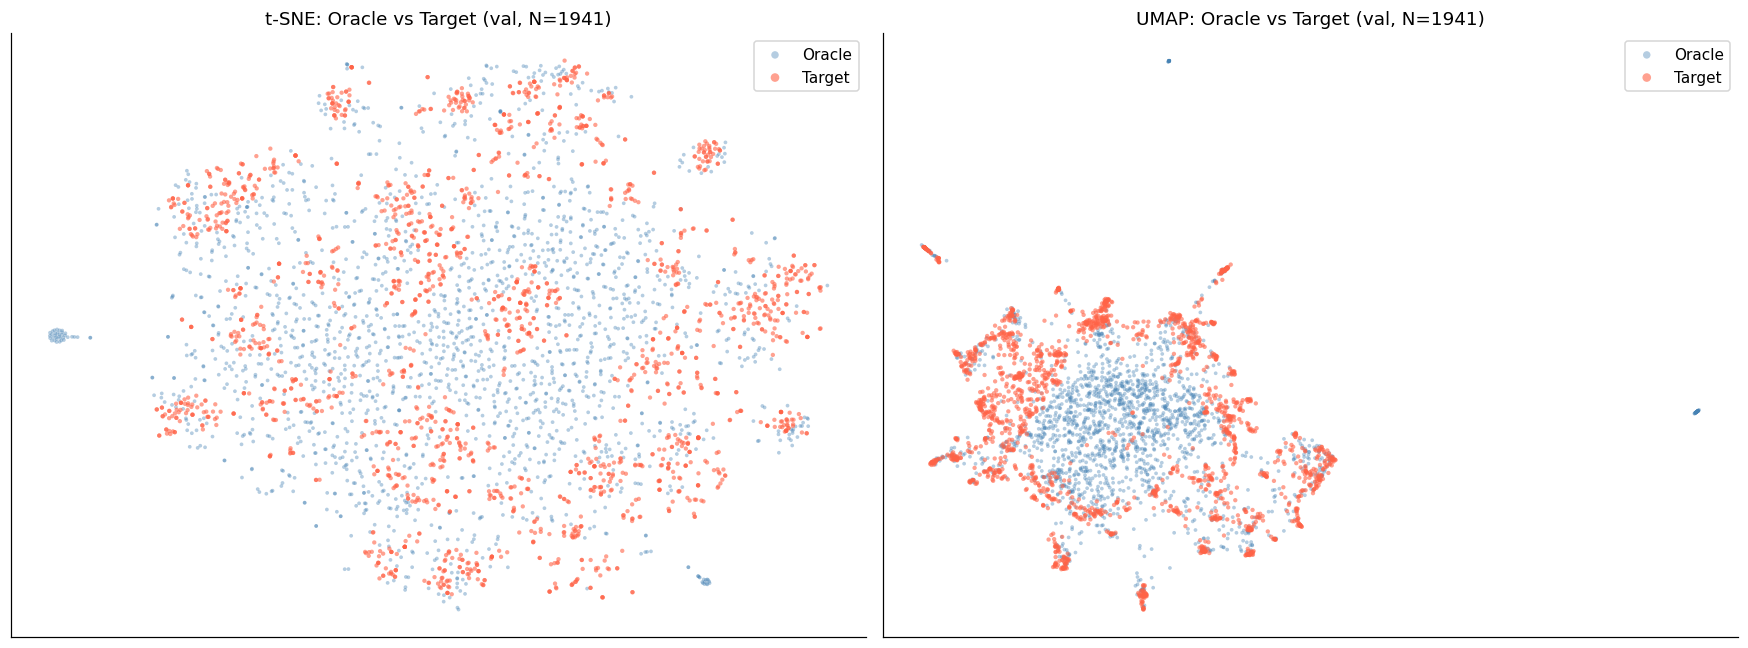

In [12]:

# ════════════════════════════════════════════════════════════
# t-SNE и UMAP: oracle vs реальные таргет-эмбеддинги (val)
# ════════════════════════════════════════════════════════════

torch.manual_seed(SEED)
model.eval()

all_oracles, all_targets_emb = [], []

with torch.no_grad():
    for batch in loaders['val']:
        history = batch['history'].to(device)
        mask    = batch['mask'].to(device)
        target  = batch['target'].to(device)
        h      = model.encode_history(history, mask, apply_cfg_dropout=False)
        oracle = model.sample(h)
        t_emb  = model.item_embedding(target)
        all_oracles.append(oracle.cpu())
        all_targets_emb.append(t_emb.cpu())

oracles = torch.cat(all_oracles, dim=0).numpy()
targets = torch.cat(all_targets_emb, dim=0).numpy()

N = len(oracles)
X = np.concatenate([oracles, targets], axis=0)
labels = np.array(['Oracle'] * N + ['Target'] * N)
print(f'Fitting on {2*N} vectors ({N} oracle + {N} target), d={X.shape[1]}')

# ── t-SNE ────────────────────────────────────────────────────
from sklearn.manifold import TSNE
tsne   = TSNE(n_components=2, perplexity=40, random_state=SEED, n_jobs=-1)
X_tsne = tsne.fit_transform(X)
print('t-SNE done')

# ── UMAP ─────────────────────────────────────────────────────
try:
    import umap
    reducer = umap.UMAP(n_components=2, random_state=SEED)
    X_umap  = reducer.fit_transform(X)
    has_umap = True
    print('UMAP done')
except ImportError:
    has_umap = False
    print('UMAP not installed. Showing only t-SNE.')

# ── Графики ──────────────────────────────────────────────────
n_plots = 2 if has_umap else 1
fig, axes = plt.subplots(1, n_plots, figsize=(8 * n_plots, 6))
if n_plots == 1:
    axes = [axes]

colors = {'Oracle': 'steelblue', 'Target': 'tomato'}
alpha  = {'Oracle': 0.4,         'Target': 0.6}
size   = {'Oracle': 6,            'Target': 8}

for ax, (title, X_2d) in zip(axes, [('t-SNE', X_tsne)] + ([('UMAP', X_umap)] if has_umap else [])):
    for label in ['Oracle', 'Target']:
        m = labels == label
        ax.scatter(X_2d[m, 0], X_2d[m, 1],
                   c=colors[label], alpha=alpha[label],
                   s=size[label], label=label, edgecolors='none')
    ax.set_title(f'{title}: Oracle vs Target (val, N={N})', fontsize=12)
    ax.legend(fontsize=10, markerscale=2)
    ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()